In [1]:
import pickle

## Load Important Function


In [2]:
class Data:
    def __init__(self, array_list):
        self.array_list = array_list

    def save(self, filename):
        with open(filename, 'wb') as f:
            pickle.dump(self.array_list, f)

    @classmethod
    def load(cls, filename):
        with open(filename, 'rb') as f:
            array_list = pickle.load(f)
        return cls(array_list)
    

## Plain MD

In [3]:
plain_md_path = '../Plain_MD/analysis'


omega_loaded = Data.load(f"{plain_md_path}/autocoorel_data/stationary_distributions_1us_5000stride.pkl").array_list
pi_all_means = omega_loaded[0]
pi_all_uppers = omega_loaded[1]
pi_all_lowers = omega_loaded[2]
pi_all_stds = omega_loaded[3]
t2_all_means = omega_loaded[4]
t2_all_uppers = omega_loaded[5]
t2_all_lowers = omega_loaded[6]
t2_all_stds = omega_loaded[7]
lagtimes_ns = omega_loaded[8]

plain_md_lagtimes_ns = lagtimes_ns
plain_md_t2_all_means = t2_all_means
plain_md_t2_all_uppers = t2_all_uppers
plain_md_t2_all_lowers = t2_all_lowers
plain_md_t2_all_stds = t2_all_stds

## EE

In [4]:
ee_path = '../EE/analysis'

omega_loaded = Data.load(f"{ee_path}/autocoorel_data/stationary_distributions.pkl").array_list
pi_all_means = omega_loaded[0]
pi_all_uppers = omega_loaded[1]
pi_all_lowers = omega_loaded[2]
pi_all_stds = omega_loaded[3]
t2_all_means = omega_loaded[4]
t2_all_uppers = omega_loaded[5]
t2_all_lowers = omega_loaded[6]
t2_all_stds = omega_loaded[7]
lagtimes_ns = omega_loaded[8]

ee_lagtimes_ns = lagtimes_ns
ee_t2_all_means = t2_all_means
ee_t2_all_uppers = t2_all_uppers
ee_t2_all_lowers = t2_all_lowers
ee_t2_all_stds = t2_all_stds

## HREX

In [5]:
hrex_path = '../HREX/analysis'

omega_loaded = Data.load(f"{hrex_path}/autocoorel_data/stationary_distributions.pkl").array_list
pi_all_means = omega_loaded[0]
pi_all_uppers = omega_loaded[1]
pi_all_lowers = omega_loaded[2]
pi_all_stds = omega_loaded[3]
t2_all_means = omega_loaded[4]
t2_all_uppers = omega_loaded[5]
t2_all_lowers = omega_loaded[6]
t2_all_stds = omega_loaded[7]
lagtimes_ns = omega_loaded[8]

hrex_lagtimes_ns = lagtimes_ns
hrex_t2_all_means = t2_all_means
hrex_t2_all_uppers = t2_all_uppers
hrex_t2_all_lowers = t2_all_lowers
hrex_t2_all_stds = t2_all_stds

## REDs

In [6]:
reds_path = '../REDs/analysis'

omega_loaded = Data.load(f"{reds_path}/autocoorel_data/stationary_distributions.pkl").array_list
pi_all_means = omega_loaded[0]
pi_all_uppers = omega_loaded[1]
pi_all_lowers = omega_loaded[2]
pi_all_stds = omega_loaded[3]
t2_all_means = omega_loaded[4]
t2_all_uppers = omega_loaded[5]
t2_all_lowers = omega_loaded[6]
t2_all_stds = omega_loaded[7]
lagtimes_ns = omega_loaded[8]

reds_lagtimes_ns = lagtimes_ns
reds_t2_all_means = t2_all_means
reds_t2_all_uppers = t2_all_uppers
reds_t2_all_lowers = t2_all_lowers
reds_t2_all_stds = t2_all_stds


## Combined Plot

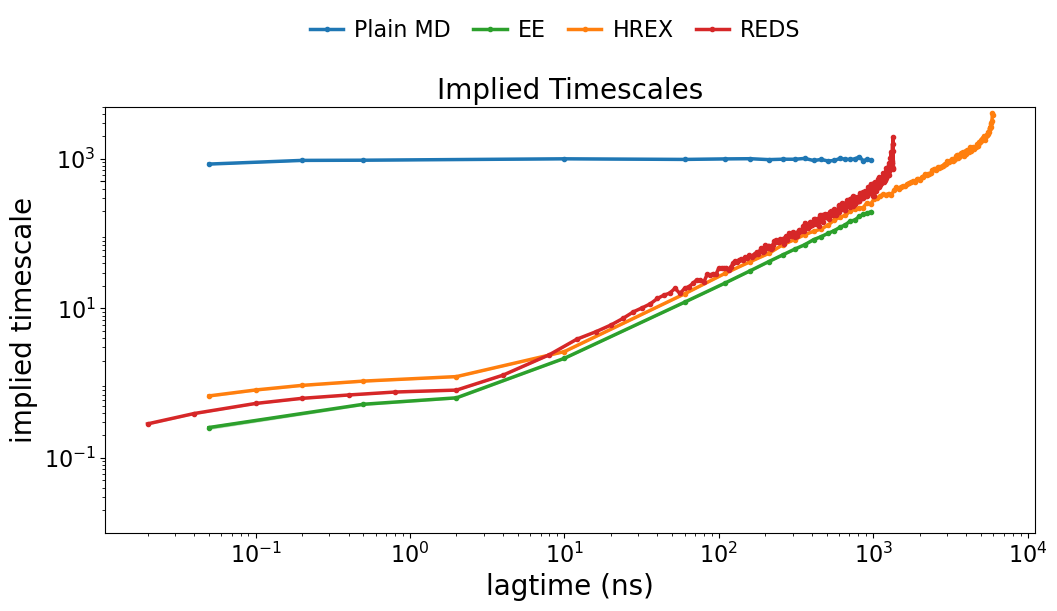

In [7]:
import matplotlib.pyplot as plt

# ==========================================
# 1. GLOBAL PLOT SETTINGS & COLORS
# ==========================================
MARKER_STYLE = '.'       # 'o' for dots, 's' for squares, None for no markers
LINE_STYLE   = '-'       # '-' for solid, '--' for dashed
LINE_WIDTH   = 2.5       # Thickness of the main lines
LINE_ALPHA   = 1.0       # Transparency of the main lines (0 to 1)
FILL_ALPHA   = 0.3      # Transparency of the shaded error regions (0 to 1)

# Ensure these keys EXACTLY match the "label" values in the datasets below
from plotting_style import METHOD_COLORS, AXIS_LABEL_FONTSIZE, TICK_FONTSIZE, LEGEND_FONTSIZE

method_colors = METHOD_COLORS

# ==========================================
# 2. DATA CONFIGURATION
# ==========================================
# NOTE: implied timescales come from MSM (transition-matrix) eigenvalues, which are
# not valid for a metadynamics-biased trajectory (there is no well-defined kinetic
# timescale without unbiasing the dynamics itself, unlike a population/free energy
# which can be bias-reweighted). All metadynamics variants are therefore dropped from this comparison entirely --
# there is no valid non-MSM substitute for a timescale, unlike the late-block
# population reference used for the stationary-population comparisons.
datasets = [
    {
        "label": "Plain MD", "dt": 0.01,
        "x": plain_md_lagtimes_ns, "y": plain_md_t2_all_means,
        "upper": plain_md_t2_all_uppers, "lower": plain_md_t2_all_lowers
    },
    {
        "label": "EE", "dt": 0.01,
        "x": ee_lagtimes_ns, "y": ee_t2_all_means,               
        "upper": ee_t2_all_uppers, "lower": ee_t2_all_lowers     
    },
    {
        "label": "HREX", "dt": 0.01,
        "x": hrex_lagtimes_ns, "y": hrex_t2_all_means,
        "upper": hrex_t2_all_uppers, "lower": hrex_t2_all_lowers
    },
    {
        "label": "REDS", "dt": 0.004,
        "x": reds_lagtimes_ns, "y": reds_t2_all_means,
        "upper": reds_t2_all_uppers, "lower": reds_t2_all_lowers
    },
]

# ==========================================
# 3. MASTER PLOTTING LOOP
# ==========================================
fig, ax = plt.subplots(figsize=(12, 6))

for data in datasets:
    dt = data["dt"]
    x = data["x"]
    y = data["y"] * dt
    y_upper = data["upper"] * dt
    y_lower = data["lower"] * dt
    
    # Map the color directly from our dictionary
    color = method_colors[data["label"]]
    
    # Plot the line and markers
    ax.plot(x, y, label=data["label"], color=color, 
            marker=MARKER_STYLE, linestyle=LINE_STYLE, 
            alpha=LINE_ALPHA, linewidth=LINE_WIDTH)
             
    # Plot the shaded confidence intervals
    ax.fill_between(x, y_upper, y_lower, color=color, alpha=FILL_ALPHA)

# ==========================================
# 4. FORMATTING & LEGEND
# ==========================================
ax.set_xlabel('lagtime (ns)', fontsize=AXIS_LABEL_FONTSIZE)
ax.set_ylabel('implied timescale', fontsize=AXIS_LABEL_FONTSIZE)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylim(0.01, 5000)
ax.set_yticks([ 0.1, 10, 1000, 500])
ax.set_title('Implied Timescales', fontsize=AXIS_LABEL_FONTSIZE)
# Change tick font size specifically for this plot
ax.tick_params(axis='both', which='major', labelsize=TICK_FONTSIZE)

# Extract handles and labels for the custom legend
handles, labels = ax.get_legend_handles_labels()

# Apply your custom legend at the Figure level
leg = fig.legend(
    handles, 
    labels, 
    loc='upper center',         
    bbox_to_anchor=(0.5, 1),  # Positioned at the very top
    ncol=len(labels),            # one row: exactly the methods actually plotted
    frameon=False, 
    handlelength=1.5,
    handletextpad=0.5,
    columnspacing=1.0,
    fontsize=LEGEND_FONTSIZE
)

# Push the plot down slightly so the title and top-legend don't overlap
plt.subplots_adjust(top=0.82)
plt.savefig('fig/main_implied_timescales_8_conformation.pdf', dpi=300, bbox_inches='tight')
plt.show()


## SI: methods-wise view

A methods-wise companion to the combined single-panel comparison above
(`fig/main_implied_timescales_8_conformation.pdf`): one panel per method
instead of all four overlaid on shared axes, so each method's own
mean-±-band curve is readable without the others' overlap/occlusion.

Unlike every other notebook's methods-wise figure, each panel here has
**exactly one curve**, not several colored by conformation-state or residue:
the 8-state implied timescale (`t2`) is a single global MSM
relaxation-mode value per method (the slowest eigenvalue of the whole 8x8
transition matrix), not a per-state quantity the way population or error is
-- there is no `t2` "for state ccc" vs "for state ctt" to decompose and
color separately. Each panel's single curve is colored with that method's
own `METHOD_COLORS` entry, for visual continuity with the rest of the paper,
rather than inventing a fake multi-color legend where only one series
exists.

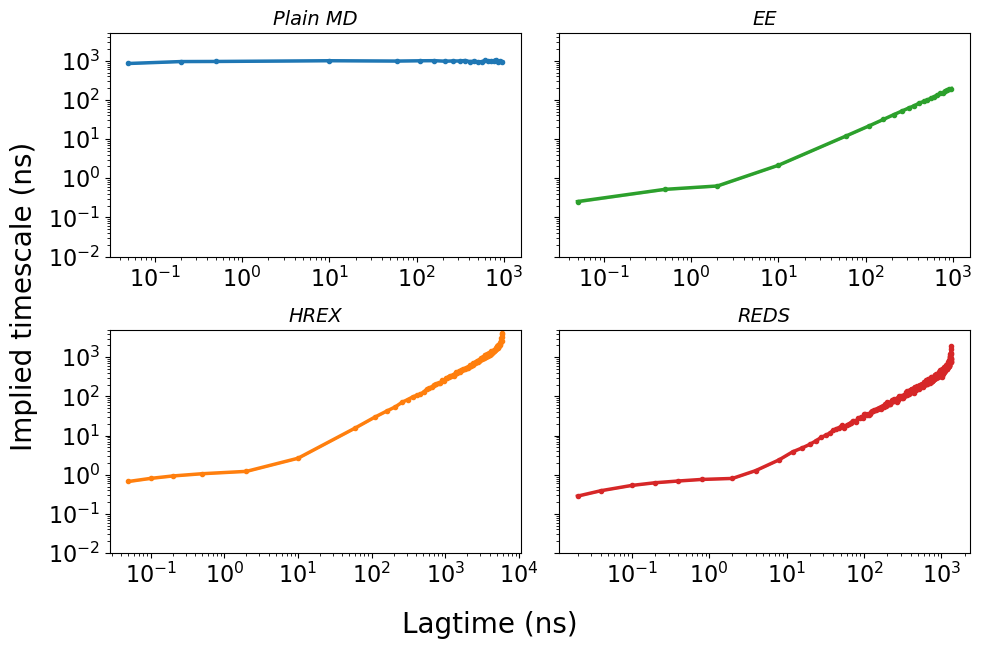

In [8]:
from plotting_style import TITLE_FONTSIZE, style_panel


def plot_method_grid_implied_timescale_8conform(datasets, savepath, ncols=2, ylim=(0.01, 5000)):
    """datasets: list of {"label","dt","x","y","upper","lower"} dicts, same shape as
    the module-level `datasets` above. One panel per method, each with its own
    single mean-+/-band t2-vs-lagtime curve (see markdown above for why there is
    only one curve per panel here, unlike every other methods-wise figure)."""
    nrows = -(-len(datasets) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), sharey=True)
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for idx, data in enumerate(datasets):
        ax = axes[idx]
        dt = data["dt"]
        x = data["x"]
        y = data["y"] * dt
        color = method_colors[data["label"]]

        ax.plot(x, y, color=color, marker=MARKER_STYLE, linestyle=LINE_STYLE,
                 alpha=LINE_ALPHA, linewidth=LINE_WIDTH)
        ax.fill_between(x, data["upper"] * dt, data["lower"] * dt, color=color, alpha=FILL_ALPHA)

        style_panel(ax, data["label"], tick_fontsize=16, title_fontsize=TITLE_FONTSIZE)
        ax.set_yscale('log')
        ax.set_xscale('log')
        ax.set_ylim(*ylim)

    for idx in range(len(datasets), len(axes)):
        axes[idx].axis("off")

    fig.supxlabel('Lagtime (ns)', fontsize=20)
    fig.supylabel('Implied timescale (ns)', fontsize=20)

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


plot_method_grid_implied_timescale_8conform(datasets, "fig/SI_implied_timescale_8conform_by_method.pdf", ncols=2)